## State-based optimisation for SQEs

In [2]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_state import sqe_optimisation
from pulse_vqe_entanglement.plotting_state import plot_sqe_optimisation

### Strong initiallisation

Tracing control amplitude graph.
Infidelity: I=2.498e-12, nit=6, success=True, grad_norm=1.624e-06, S=3.975e-01
[outer 00] I=6.797e-10, lam=7.786969e+00, inner_nit=37, inner_success=True, constraint_residual=6.787e-10, S=5.112e-08
[outer 01] I=1.091e-11, lam=7.886083e+00, inner_nit=2, inner_success=True, constraint_residual=9.911e-12, S=5.226e-08
[outer 02] I=1.042e-11, lam=7.980275e+00, inner_nit=1, inner_success=True, constraint_residual=9.419e-12, S=5.227e-08
[outer 03] I=9.919e-12, lam=8.069463e+00, inner_nit=1, inner_success=True, constraint_residual=8.919e-12, S=5.227e-08
[outer 04] I=9.370e-12, lam=8.153167e+00, inner_nit=1, inner_success=True, constraint_residual=8.370e-12, S=5.227e-08


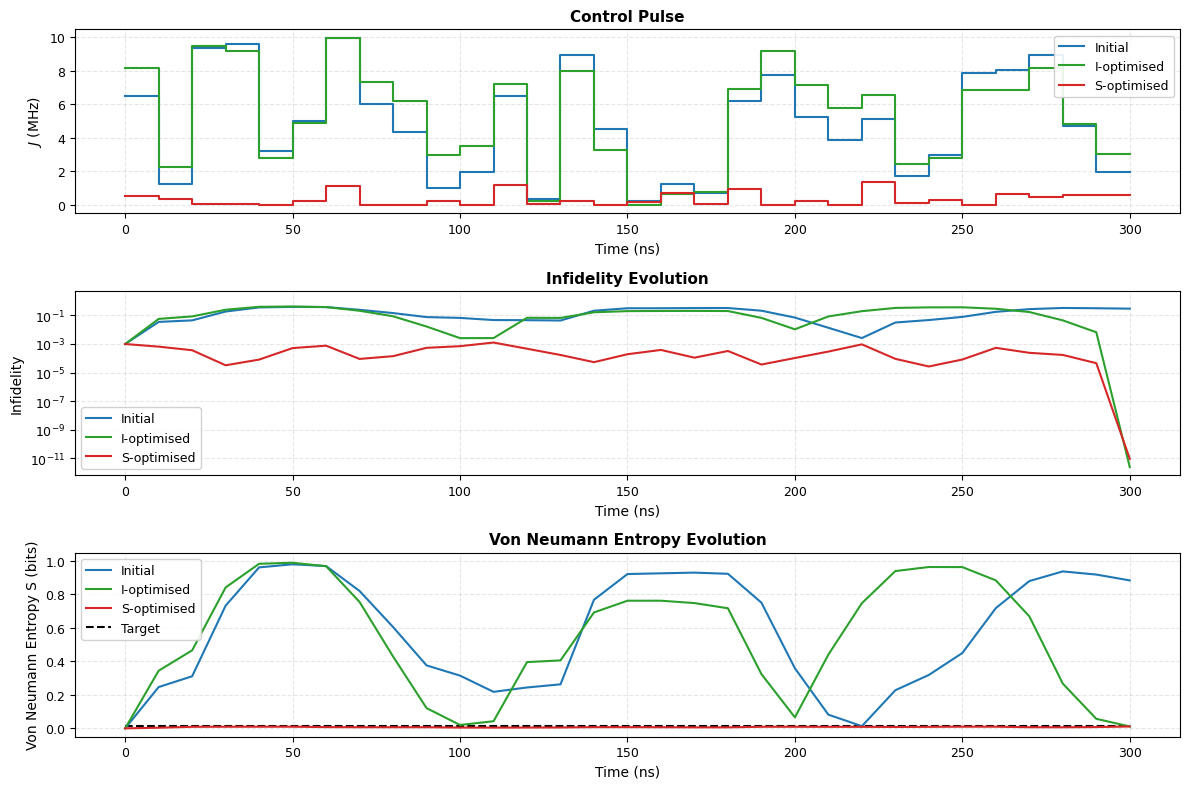

In [6]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=30,
    n_discretisation=1,
    T=300.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e0,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=500,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)

### Weak initialisation

Tracing control amplitude graph.
Infidelity: I=1.415e-11, nit=4, success=True, grad_norm=4.488e-06, S=8.003e-08
[outer 00] I=1.856e-09, lam=1.955414e+01, inner_nit=4, inner_success=True, constraint_residual=1.855e-09, S=7.626e-08
[outer 01] I=4.961e-12, lam=1.959376e+01, inner_nit=2, inner_success=True, constraint_residual=3.961e-12, S=7.976e-08
[outer 02] I=5.119e-12, lam=1.963495e+01, inner_nit=1, inner_success=True, constraint_residual=4.119e-12, S=7.976e-08
[outer 03] I=4.661e-12, lam=1.967156e+01, inner_nit=1, inner_success=True, constraint_residual=3.661e-12, S=7.976e-08
[outer 04] I=5.181e-12, lam=1.971337e+01, inner_nit=1, inner_success=True, constraint_residual=4.181e-12, S=7.975e-08


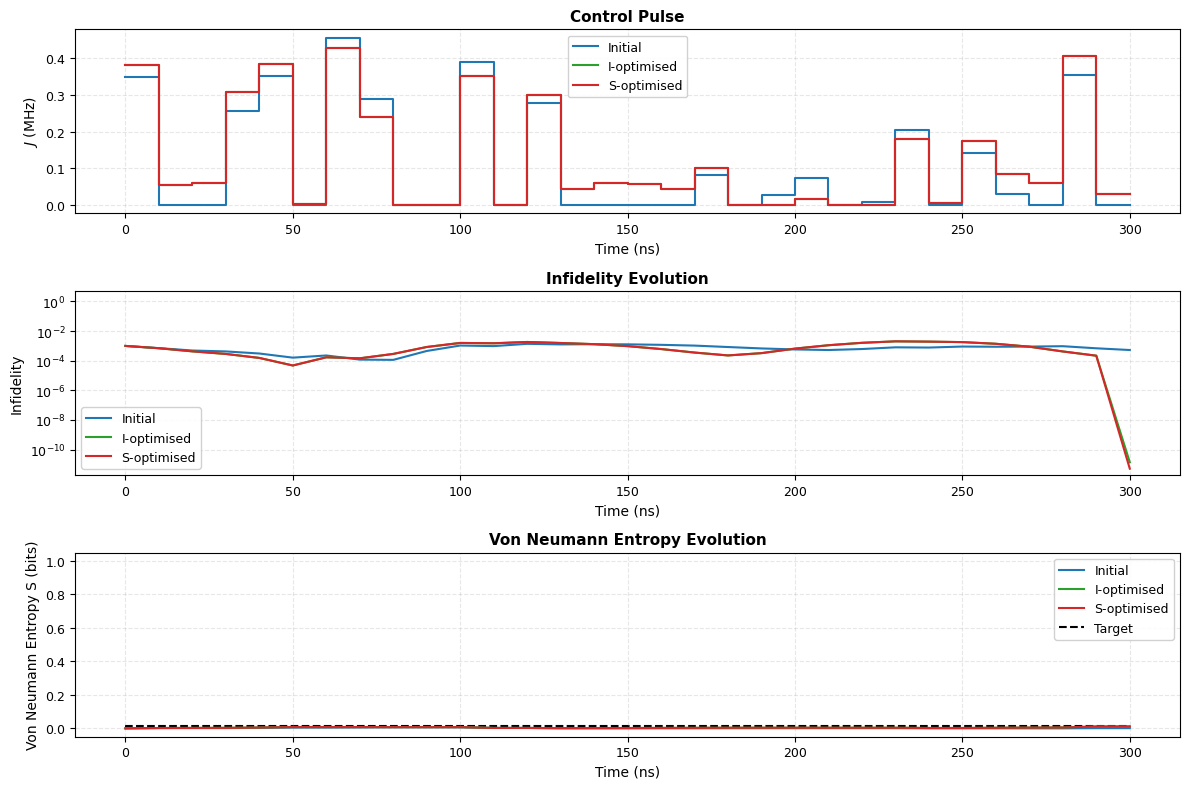

In [8]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=30,
    n_discretisation=1,
    T=300.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=-1.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=500,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)